# Logistic Regression with Adam
**Dataset:** Body Performance Data (Kaggle), 13,393 people, fitness test results
**Goal:** predict if a person has **high fitness (class A or B = 1)** or **lower fitness (class C or D = 0)**
**Metrics:** Accuracy, Precision, Recall, F1 and Loss

## 1. Import libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

## 2. Load the data

In [2]:
# find bodyPerformance.csv (works on Kaggle and on a normal computer)
data_path = 'bodyPerformance.csv'
for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        if f.lower() == 'bodyperformance.csv':
            data_path = os.path.join(root, f)

df = pd.read_csv(data_path)
print('Shape:', df.shape)
df.head()

Shape: (13393, 12)


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
1,25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
2,31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
3,32.0,M,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
4,28.0,M,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13393 entries, 0 to 13392
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      13393 non-null  float64
 1   gender                   13393 non-null  str    
 2   height_cm                13393 non-null  float64
 3   weight_kg                13393 non-null  float64
 4   body fat_%               13393 non-null  float64
 5   diastolic                13393 non-null  float64
 6   systolic                 13393 non-null  float64
 7   gripForce                13393 non-null  float64
 8   sit and bend forward_cm  13393 non-null  float64
 9   sit-ups counts           13393 non-null  float64
 10  broad jump_cm            13393 non-null  float64
 11  class                    13393 non-null  str    
dtypes: float64(10), str(2)
memory usage: 1.2 MB


In [4]:
print(df['class'].value_counts().sort_index())

class
A    3348
B    3347
C    3349
D    3349
Name: count, dtype: int64


## 3. Prepare the data
- `gender`: M → 1, F → 0
- **Target (binary):** classes **A and B → 1 (high fitness)**, classes **C and D → 0 (lower fitness)**
- Features: all the other 11 columns

In [5]:
df['gender'] = df['gender'].map({'M': 1, 'F': 0})
df['target'] = df['class'].isin(['A', 'B']).astype(int)

X = df.drop(['class', 'target'], axis=1).values
y = df['target'].values

print('Features:', list(df.drop(['class', 'target'], axis=1).columns))
print('Class balance (share of 1):', round(y.mean(), 3))

Features: ['age', 'gender', 'height_cm', 'weight_kg', 'body fat_%', 'diastolic', 'systolic', 'gripForce', 'sit and bend forward_cm', 'sit-ups counts', 'broad jump_cm']
Class balance (share of 1): 0.5


## 4. Split 80% train / 20% test, then scale

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# add a column of 1s for the bias (intercept)
X_train_b = np.c_[np.ones(len(X_train)), X_train]
X_test_b = np.c_[np.ones(len(X_test)), X_test]

print('Train:', X_train_b.shape, ' Test:', X_test_b.shape)

Train: (10714, 12)  Test: (2679, 12)


## 5. Logistic Regression functions

- **Sigmoid** turns any number into a probability between 0 and 1:  $\sigma(z) = \frac{1}{1 + e^{-z}}$
- **Prediction:** $p = \sigma(Xw)$, and we say class 1 if $p \ge 0.5$
- **Loss (Binary Cross-Entropy):**  $J(w) = -\frac{1}{m}\sum \big[y\log(p) + (1-y)\log(1-p)\big]$
- **Gradient:**  $\nabla J(w) = \frac{1}{m} X^T (p - y)$

In [7]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def predict_proba(X, w):
    return sigmoid(X @ w)

def predict(X, w, threshold=0.5):
    return (predict_proba(X, w) >= threshold).astype(int)

def compute_loss(X, y, w):
    p = predict_proba(X, w)
    p = np.clip(p, 1e-15, 1 - 1e-15)          # avoid log(0)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def compute_gradient(X, y, w):
    p = predict_proba(X, w)
    return X.T @ (p - y) / len(y)

## 6. Evaluation metrics (written by hand)

|  | Predicted 1 | Predicted 0 |
|---|---|---|
| **Actual 1** | TP | FN |
| **Actual 0** | FP | TN |

- **Accuracy** = (TP + TN) / all
- **Precision** = TP / (TP + FP) → from the people we said are "high fitness", how many really are
- **Recall** = TP / (TP + FN) → from the people who really are "high fitness", how many we found
- **F1** = 2 · Precision · Recall / (Precision + Recall)

In [8]:
def evaluate(X, y, w):
    y_pred = predict(X, w)
    TP = np.sum((y_pred == 1) & (y == 1))
    TN = np.sum((y_pred == 0) & (y == 0))
    FP = np.sum((y_pred == 1) & (y == 0))
    FN = np.sum((y_pred == 0) & (y == 1))

    accuracy = (TP + TN) / len(y)
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

    return {'Loss': compute_loss(X, y, w), 'Accuracy': accuracy, 'Precision': precision,
            'Recall': recall, 'F1': f1, 'cm': np.array([[TP, FN], [FP, TN]])}

## 7. Train with Adam

**Adam** = **Momentum** (moving average of the gradients, `m_t`) + **RMSprop** (moving average of the squared gradients, `v_t`),
with bias correction at the start.

$m = \beta_1 m + (1-\beta_1) g$

$v = \beta_2 v + (1-\beta_2) g^2$

$\hat m = \frac{m}{1-\beta_1^t}, \quad \hat v = \frac{v}{1-\beta_2^t}$

$w = w - \alpha \frac{\hat m}{\sqrt{\hat v} + \epsilon}$

In [9]:
learning_rate = 0.01
beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8
epochs = 50
batch_size = 64

w = np.zeros(X_train_b.shape[1])
m_t = np.zeros_like(w)          # first moment (momentum)
v_t = np.zeros_like(w)          # second moment (squared gradients)
t = 0
losses = []
m = len(y_train)

for epoch in range(epochs):
    indices = np.random.permutation(m)
    X_shuffled = X_train_b[indices]
    y_shuffled = y_train[indices]

    for start in range(0, m, batch_size):
        X_batch = X_shuffled[start:start + batch_size]
        y_batch = y_shuffled[start:start + batch_size]
        g = compute_gradient(X_batch, y_batch, w)

        t += 1
        m_t = beta1 * m_t + (1 - beta1) * g
        v_t = beta2 * v_t + (1 - beta2) * g ** 2
        m_hat = m_t / (1 - beta1 ** t)
        v_hat = v_t / (1 - beta2 ** t)
        w = w - learning_rate * m_hat / (np.sqrt(v_hat) + epsilon)

    losses.append(compute_loss(X_train_b, y_train, w))
    if epoch % 5 == 0:
        print(f'Epoch {epoch}: loss = {losses[-1]:.4f}')

print('Final training loss:', round(losses[-1], 4))

Epoch 0: loss = 0.4100
Epoch 5: loss = 0.3799
Epoch 10: loss = 0.3798
Epoch 15: loss = 0.3802
Epoch 20: loss = 0.3821
Epoch 25: loss = 0.3800
Epoch 30: loss = 0.3799
Epoch 35: loss = 0.3796
Epoch 40: loss = 0.3796
Epoch 45: loss = 0.3796
Final training loss: 0.3796


## 8. Loss curve

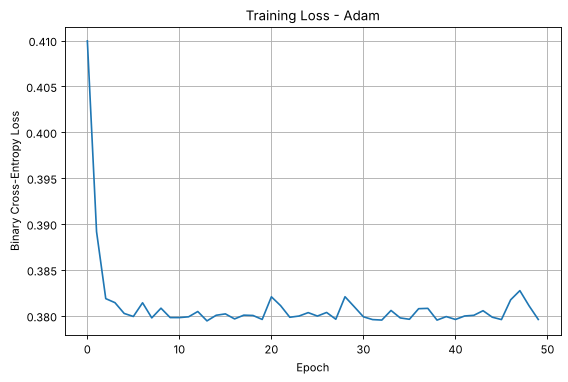

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(losses)
plt.title('Training Loss - Adam')
plt.xlabel('Epoch')
plt.ylabel('Binary Cross-Entropy Loss')
plt.grid(True)
plt.show()

## 9. Results on train and test

In [11]:
train_res = evaluate(X_train_b, y_train, w)
test_res = evaluate(X_test_b, y_test, w)

results = pd.DataFrame({
    'Train': {k: v for k, v in train_res.items() if k != 'cm'},
    'Test': {k: v for k, v in test_res.items() if k != 'cm'},
}).round(4)
results

,Train,Test
Loss,0.3796,0.3920
Accuracy,0.8301,0.8227
Precision,0.8197,0.8081
Recall,0.8463,0.8462
F1,0.8328,0.8267


## 10. Confusion matrix (test set)

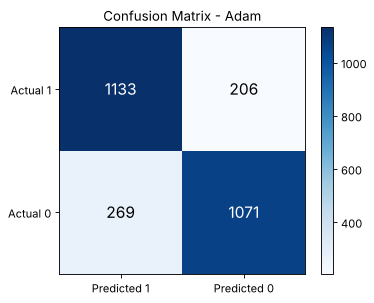

In [12]:
cm = test_res['cm']
plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center', fontsize=14,
                 color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.xticks([0, 1], ['Predicted 1', 'Predicted 0'])
plt.yticks([0, 1], ['Actual 1', 'Actual 0'])
plt.title('Confusion Matrix - Adam')
plt.colorbar()
plt.show()

## 11. Check: compare our metrics with scikit-learn

In [13]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss

y_pred = predict(X_test_b, w)
print('Accuracy :', round(accuracy_score(y_test, y_pred), 4))
print('Precision:', round(precision_score(y_test, y_pred), 4))
print('Recall   :', round(recall_score(y_test, y_pred), 4))
print('F1       :', round(f1_score(y_test, y_pred), 4))
print('Loss     :', round(log_loss(y_test, predict_proba(X_test_b, w)), 4))

Accuracy : 0.8227
Precision: 0.8081
Recall   : 0.8462
F1       : 0.8267
Loss     : 0.392
